<a href="https://colab.research.google.com/github/KelvinMaulanaUndira/Kantin_Emak_Dian/blob/main/Kelvin_Maulana_411232020_P9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**KELVIN MAULANA - 411232020 PERTEMUUANN 9**

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Membuat koneksi database SQLite
conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()

# Mengaktifkan foreign key
cursor.execute("PRAGMA foreign_keys = ON")

print("Database perpustakaan berhasil dibuat!")


Database perpustakaan berhasil dibuat!


In [13]:

# Membuat tabel buku
cursor.execute("""
CREATE TABLE IF NOT EXISTS buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER
)
""")

# Membuat tabel anggota
cursor.execute("""
CREATE TABLE IF NOT EXISTS anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT UNIQUE
)
""")

# Membuat tabel peminjaman
cursor.execute("""
CREATE TABLE IF NOT EXISTS peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
)
""")

conn.commit()

print("Tiga tabel berhasil dibuat!")


Tiga tabel berhasil dibuat!


In [14]:

data_buku = [
    ('Laskar Pelangi', 'Andrea Hirata', 2005),
    ('Bumi', 'Tere Liye', 2014),
    ('Negeri 5 Menara', 'Ahmad Fuadi', 2009),
    ('Laut Bercerita', 'Leila S. Chudori', 2017),
    ('Dilan 1990', 'Pidi Baiq', 2014)
]

cursor.executemany("""
INSERT INTO buku (judul, penulis, tahun)
VALUES (?, ?, ?)
""", data_buku)

conn.commit()

print("5 data buku berhasil ditambahkan!")

df_buku = pd.read_sql_query("SELECT * FROM buku", conn)
display(df_buku)


5 data buku berhasil ditambahkan!


,id,judul,penulis,tahun
0,1,Laskar Pelangi,Andrea Hirata,2005
1,2,Bumi,Tere Liye,2014
2,3,Negeri 5 Menara,Ahmad Fuadi,2009
3,4,Laut Bercerita,Leila S. Chudori,2017
4,5,Dilan 1990,Pidi Baiq,2014
5,6,Laskar Pelangi,Andrea Hirata,2005
6,7,Bumi,Tere Liye,2014
7,8,Negeri 5 Menara,Ahmad Fuadi,2009
8,9,Laut Bercerita,Leila S. Chudori,2017
9,10,Dilan 1990,Pidi Baiq,2014


In [17]:
data_anggota = [
    ('Andi Saputra', 'andi@gmail.com'),
    ('Budi Santoso', 'budi@gmail.com'),
    ('Citra Lestari', 'citra@gmail.com')
]

# Menggunakan INSERT OR IGNORE untuk menghindari error duplikasi email
cursor.executemany("""
INSERT OR IGNORE INTO anggota (nama, email)
VALUES (?, ?)
""", data_anggota)

conn.commit()

print("Data anggota berhasil ditambahkan (duplikasi dilewati jika ada)!")

df_anggota = pd.read_sql_query("SELECT * FROM anggota", conn)
display(df_anggota)

Data anggota berhasil ditambahkan (duplikasi dilewati jika ada)!


,id,nama,email
0,1,Andi Saputra,andi@gmail.com
1,2,Budi Santoso,budi@gmail.com
2,3,Citra Lestari,citra@gmail.com


In [18]:

data_peminjaman = [
    (1, 1, '2026-11-01', '2026-11-07'),
    (2, 2, '2026-11-03', '2026-11-10'),
    (1, 3, '2026-11-05', None),
    (3, 4, '2026-11-08', '2026-11-15')
]

cursor.executemany("""
INSERT INTO peminjaman
(id_anggota, id_buku, tgl_pinjam, tgl_kembali)
VALUES (?, ?, ?, ?)
""", data_peminjaman)

conn.commit()

print("4 transaksi peminjaman berhasil ditambahkan!")

df_peminjaman = pd.read_sql_query(
    "SELECT * FROM peminjaman", conn
)
display(df_peminjaman)


4 transaksi peminjaman berhasil ditambahkan!


,id,id_anggota,id_buku,tgl_pinjam,tgl_kembali
0,1,1,1,2026-11-01,2026-11-07
1,2,2,2,2026-11-03,2026-11-10
2,3,1,3,2026-11-05,None
3,4,3,4,2026-11-08,2026-11-15
4,5,1,1,2026-11-01,2026-11-07
5,6,2,2,2026-11-03,2026-11-10
6,7,1,3,2026-11-05,None
7,8,3,4,2026-11-08,2026-11-15


In [19]:

query_join = """
SELECT
    peminjaman.id,
    anggota.nama AS nama_anggota,
    buku.judul AS judul_buku,
    peminjaman.tgl_pinjam,
    peminjaman.tgl_kembali
FROM peminjaman
JOIN anggota
    ON peminjaman.id_anggota = anggota.id
JOIN buku
    ON peminjaman.id_buku = buku.id
"""

df_join = pd.read_sql_query(query_join, conn)

print("DAFTAR PEMINJAMAN PERPUSTAKAAN")
display(df_join)


DAFTAR PEMINJAMAN PERPUSTAKAAN


,id,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07
1,2,Budi Santoso,Bumi,2026-11-03,2026-11-10
2,3,Andi Saputra,Negeri 5 Menara,2026-11-05,None
3,4,Citra Lestari,Laut Bercerita,2026-11-08,2026-11-15
4,5,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07
5,6,Budi Santoso,Bumi,2026-11-03,2026-11-10
6,7,Andi Saputra,Negeri 5 Menara,2026-11-05,None
7,8,Citra Lestari,Laut Bercerita,2026-11-08,2026-11-15


In [20]:

query_group = """
SELECT
    anggota.nama AS nama_anggota,
    COUNT(peminjaman.id) AS jumlah_buku_dipinjam
FROM anggota
LEFT JOIN peminjaman
    ON anggota.id = peminjaman.id_anggota
GROUP BY anggota.id, anggota.nama
"""

df_group = pd.read_sql_query(query_group, conn)

print("JUMLAH BUKU YANG DIPINJAM SETIAP ANGGOTA")
display(df_group)


JUMLAH BUKU YANG DIPINJAM SETIAP ANGGOTA


,nama_anggota,jumlah_buku_dipinjam
0,Andi Saputra,4
1,Budi Santoso,2
2,Citra Lestari,2


In [21]:

# Mengambil hasil query JOIN ke DataFrame
df = pd.read_sql_query(query_join, conn)

print("DATAFRAME PEMINJAMAN PERPUSTAKAAN")
display(df)

# Melihat informasi data
print("\nInformasi Data:")
df.info()

# Melihat statistik sederhana
print("\nStatistik Data:")
display(df.describe(include='all'))


DATAFRAME PEMINJAMAN PERPUSTAKAAN


,id,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07
1,2,Budi Santoso,Bumi,2026-11-03,2026-11-10
2,3,Andi Saputra,Negeri 5 Menara,2026-11-05,None
3,4,Citra Lestari,Laut Bercerita,2026-11-08,2026-11-15
4,5,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07
5,6,Budi Santoso,Bumi,2026-11-03,2026-11-10
6,7,Andi Saputra,Negeri 5 Menara,2026-11-05,None
7,8,Citra Lestari,Laut Bercerita,2026-11-08,2026-11-15



Informasi Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            8 non-null      int64 
 1   nama_anggota  8 non-null      object
 2   judul_buku    8 non-null      object
 3   tgl_pinjam    8 non-null      object
 4   tgl_kembali   6 non-null      object
dtypes: int64(1), object(4)
memory usage: 452.0+ bytes

Statistik Data:


,id,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
count,8.00000,8,8,8,6
unique,NaN,3,4,4,3
top,NaN,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07
freq,NaN,4,2,2,2
mean,4.50000,NaN,NaN,NaN,NaN
std,2.44949,NaN,NaN,NaN,NaN
min,1.00000,NaN,NaN,NaN,NaN
25%,2.75000,NaN,NaN,NaN,NaN
50%,4.50000,NaN,NaN,NaN,NaN
75%,6.25000,NaN,NaN,NaN,NaN


In [22]:

# Mengubah kolom tanggal menjadi format datetime
df['tgl_pinjam'] = pd.to_datetime(df['tgl_pinjam'])
df['tgl_kembali'] = pd.to_datetime(df['tgl_kembali'])

# Menghitung durasi peminjaman
df['durasi_pinjam'] = (
    df['tgl_kembali'] - df['tgl_pinjam']
).dt.days

print("HASIL PERHITUNGAN DURASI PEMINJAMAN")
display(df)


HASIL PERHITUNGAN DURASI PEMINJAMAN


,id,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_pinjam
0,1,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07,6.0
1,2,Budi Santoso,Bumi,2026-11-03,2026-11-10,7.0
2,3,Andi Saputra,Negeri 5 Menara,2026-11-05,NaT,NaN
3,4,Citra Lestari,Laut Bercerita,2026-11-08,2026-11-15,7.0
4,5,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07,6.0
5,6,Budi Santoso,Bumi,2026-11-03,2026-11-10,7.0
6,7,Andi Saputra,Negeri 5 Menara,2026-11-05,NaT,NaN
7,8,Citra Lestari,Laut Bercerita,2026-11-08,2026-11-15,7.0


In [23]:

# Menghitung total transaksi peminjaman
total_transaksi = len(df)

# Menghitung jumlah buku yang sudah dikembalikan
sudah_kembali = df['tgl_kembali'].notna().sum()

# Menghitung jumlah buku yang belum dikembalikan
belum_kembali = df['tgl_kembali'].isna().sum()

# Menghitung rata-rata durasi peminjaman
rata_rata = df['durasi_pinjam'].mean()

print("HASIL EKSPLORASI DATA")
print("Total transaksi:", total_transaksi)
print("Sudah dikembalikan:", sudah_kembali)
print("Belum dikembalikan:", belum_kembali)
print("Rata-rata durasi peminjaman:",
      round(rata_rata, 2), "hari")


HASIL EKSPLORASI DATA
Total transaksi: 8
Sudah dikembalikan: 6
Belum dikembalikan: 2
Rata-rata durasi peminjaman: 6.67 hari


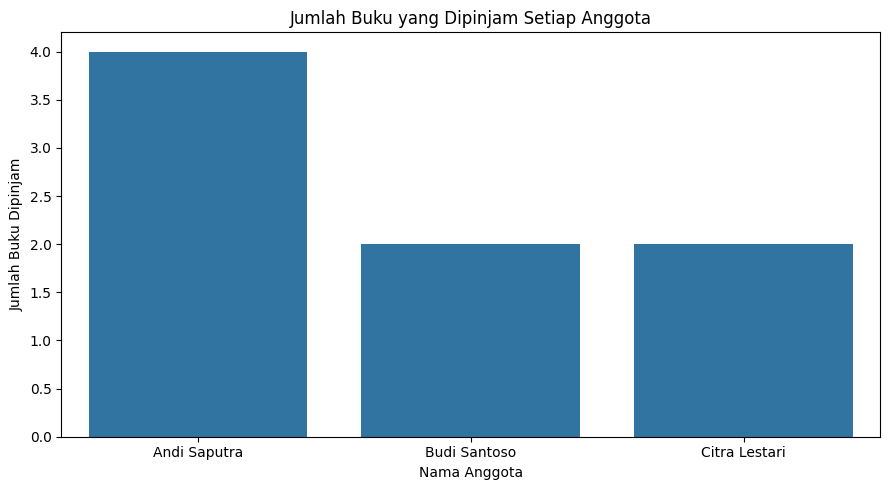

In [24]:

# Mengambil data jumlah peminjaman per anggota
df_visual = df_group

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_visual,
    x='nama_anggota',
    y='jumlah_buku_dipinjam'
)

plt.title('Jumlah Buku yang Dipinjam Setiap Anggota')
plt.xlabel('Nama Anggota')
plt.ylabel('Jumlah Buku Dipinjam')

plt.tight_layout()
plt.show()


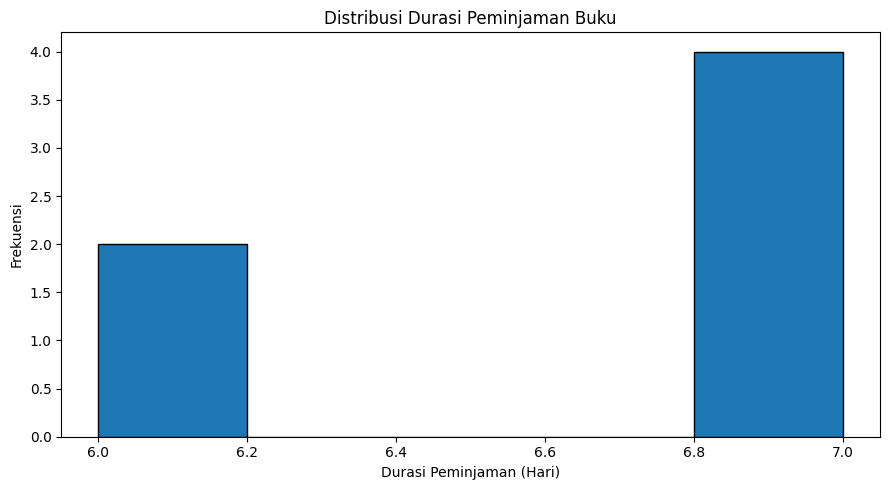

In [25]:

# Mengambil data durasi yang tidak kosong
durasi_valid = df['durasi_pinjam'].dropna()

plt.figure(figsize=(9, 5))

plt.hist(
    durasi_valid,
    bins=5,
    edgecolor='black'
)

plt.title('Distribusi Durasi Peminjaman Buku')
plt.xlabel('Durasi Peminjaman (Hari)')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()


## KESIMPULAN

Berdasarkan praktikum yang telah dilakukan, sistem basis data perpustakaan berhasil dibuat menggunakan SQLite melalui Google Colab. Sistem ini terdiri dari tiga tabel utama, yaitu tabel buku, tabel anggota, dan tabel peminjaman. Setiap tabel memiliki hubungan menggunakan Primary Key dan Foreign Key sehingga data dapat saling terhubung dengan baik.

Pada tahap pengujian, telah ditambahkan sebanyak 5 data buku, 3 data anggota, dan 4 transaksi peminjaman. Operasi JOIN berhasil digunakan untuk menampilkan informasi peminjaman secara lengkap, termasuk nama anggota dan judul buku. Selain itu, penggunaan GROUP BY dan fungsi COUNT() berhasil menghitung jumlah buku yang dipinjam oleh masing-masing anggota.

Pada tahap analisis data, library pandas digunakan untuk mengolah hasil query SQL menjadi DataFrame. Eksplorasi dilakukan dengan menghitung durasi peminjaman, jumlah buku yang telah dikembalikan, serta jumlah buku yang belum dikembalikan. Selanjutnya, visualisasi menggunakan matplotlib dan seaborn digunakan untuk menggambarkan jumlah peminjaman setiap anggota dan distribusi durasi peminjaman.

Dengan demikian, praktikum ini memberikan pemahaman mengenai pembuatan database relasional, penggunaan perintah SQL, pengolahan data menggunakan pandas, serta penyajian informasi melalui visualisasi data.